### Exploratory Data Analysis

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random


# 1. Read the dataset
try:
    # check the dataset exsistence
    NPZ_PATH = Path("../data/raw/Wafer_Map_Datasets.npz")
    if not NPZ_PATH.exists():
        raise FileNotFoundError("[System Error] Cannot find the dataset.")
    print(f"[System Info] The raw data exists: {NPZ_PATH}")

    # load the dataset
    data = np.load(NPZ_PATH)

    if data is None:
        raise FileNotFoundError("[System Error] Cannot find the dataset.")
    
    print("========== Dataset Information ==========")
    print(f"Dataset Information: {data.files}")
    images = data["arr_0"]
    labels = data["arr_1"]
    print(f"\nImage Dataset Shape: {images.shape}")
    print(f"Image Dataset Datatype: {images.dtype}")
    print(f"\nLabel Dada Shape: {labels.shape}")
    print(f"Label Dada Datatype: {labels.dtype}")

    print(f"\nThe first element of the image data:\n{images[0].tolist()}")
    print(f"\nThe first element of the label data:\n{data["arr_1"][0]}")
    print("=========================================")
except Exception as e:
    print(f"[System Info] System exception: {e}")

[System Info] The raw data exists: ../data/raw/Wafer_Map_Datasets.npz
========== Dataset Information ==========
Dataset Information: ['arr_0', 'arr_1']

Image Dataset Shape: (38015, 52, 52)
Image Dataset Datatype: int32

Label Dada Shape: (38015, 8)
Label Dada Datatype: int32

The first element of the image data:
[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 2, 1, 1, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 

### Customized Functions

/tmp/ipykernel_1682/4224298238.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Class", y="Count", data=df_counts, palette="viridis", order=df_counts["Class"])


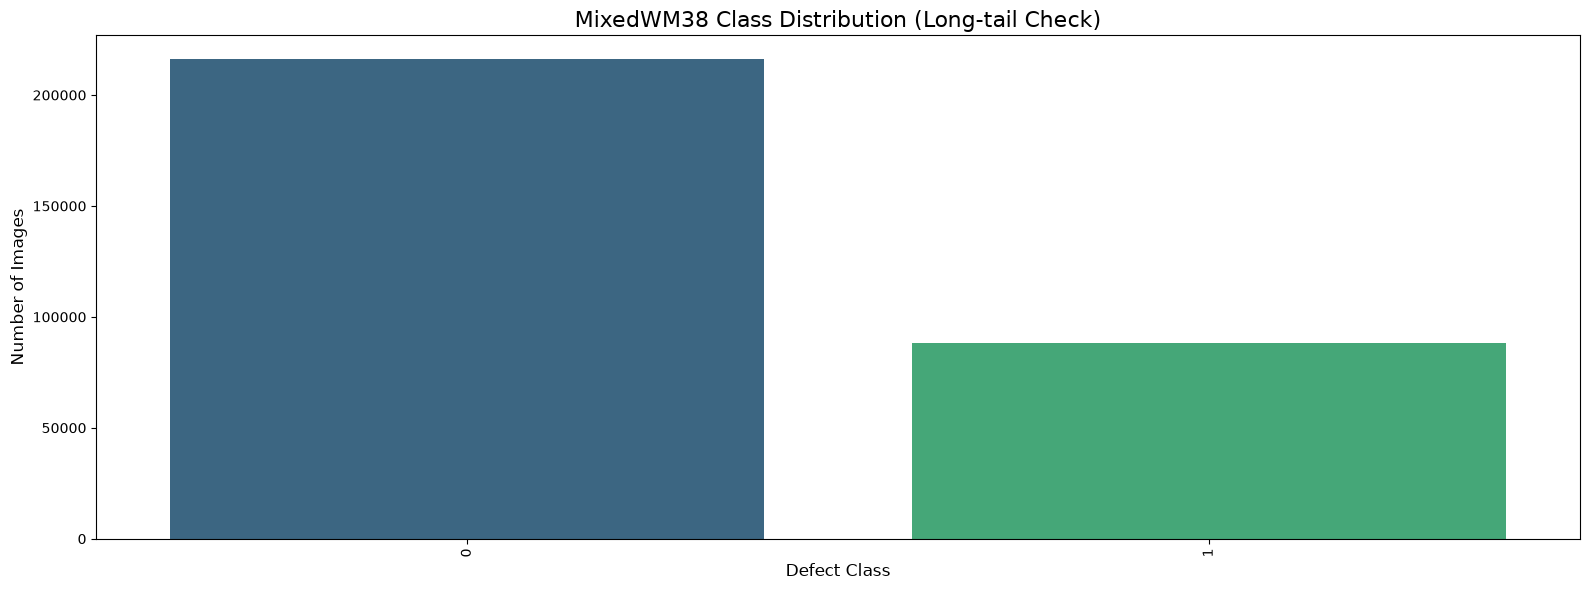

Total Images:304120
Class with the most data: Class 0 (216105 images)
Class with the lessest data: 1 (88015 images)


In [5]:
# 2. Category distribution analysis (checking for the long-tail effect)
def analysis_class_distribution(labels: np.array):
    unique_classes, counts = np.unique(labels, return_counts=True)

    df_counts = pd.DataFrame({"Class": unique_classes, "Count": counts})
    df_counts = df_counts.sort_values(by="Count", ascending=False)

    plt.figure(figsize=(16, 6))
    sns.barplot(x="Class", y="Count", data=df_counts, palette="viridis", order=df_counts["Class"])
    plt.title("MixedWM38 Class Distribution (Long-tail Check)", fontsize=16)
    plt.xlabel("Defect Class", fontsize=12)
    plt.ylabel("Number of Images", fontsize=12)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    print("=========================================")
    print(f"Total Images:{df_counts["Count"].sum()}")
    print(f"Class with the most data: Class {df_counts.iloc[0]["Class"]} ({df_counts.iloc[0]["Count"]} images)")
    print(f"Class with the lessest data: {df_counts.iloc[-1]["Class"]} ({df_counts.iloc[-1]["Count"]} images)")
    print("=========================================")
    return df_counts

try:
    df_counts = analysis_class_distribution(labels=labels)
    # print(df_counts)
except Exception as e:
    print(f"[System Info] System exception: {e}")

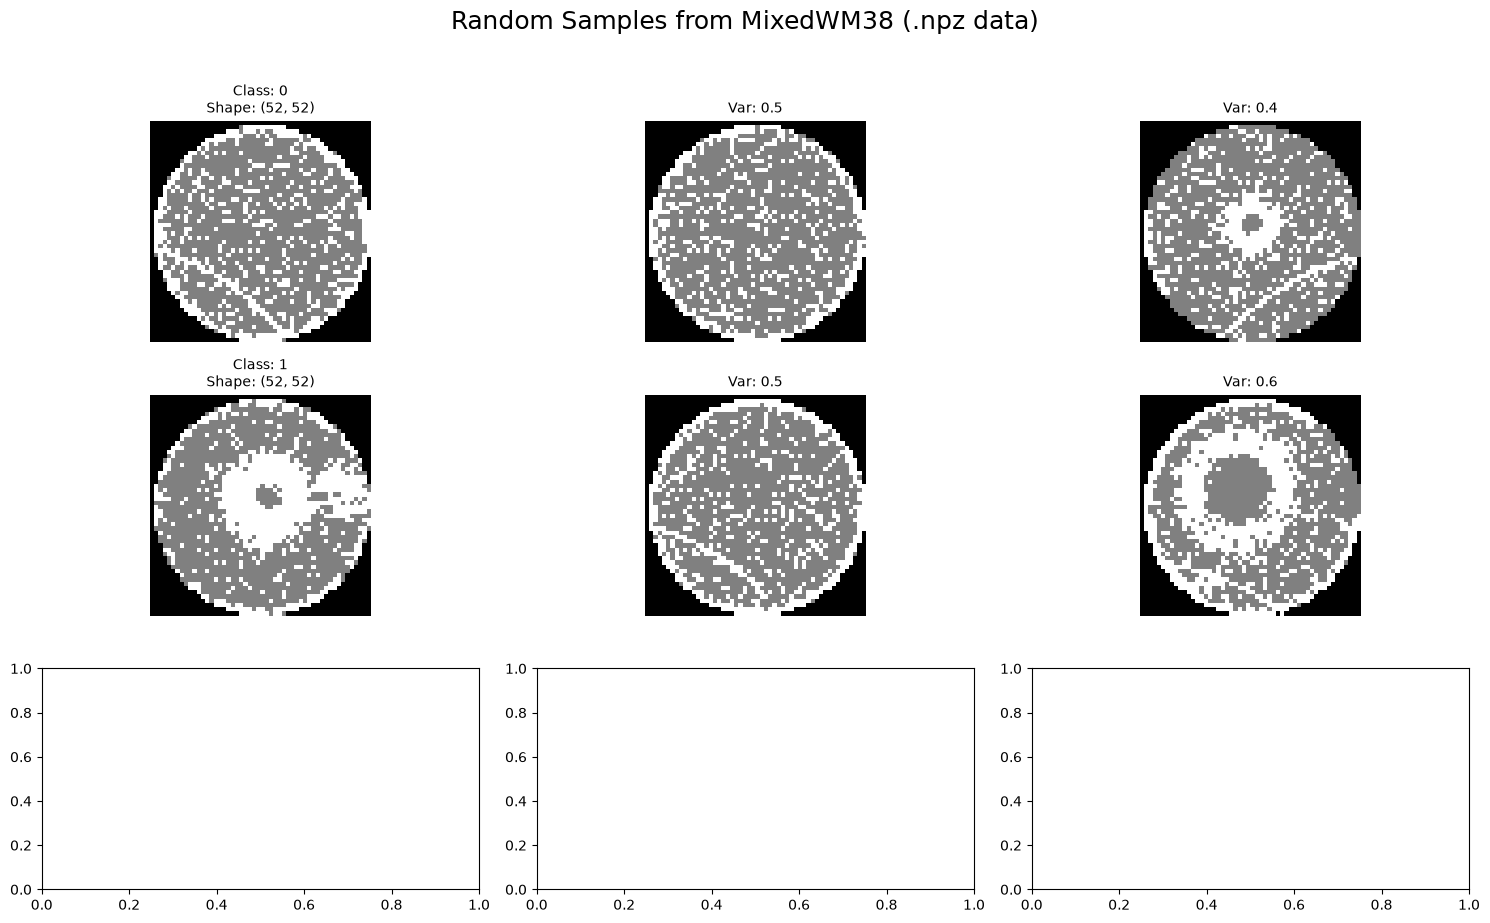

In [6]:
# 3. Observing features and noise through random sampling
def visualize_random_samples(images, labels, num_classes=6, samples_per_class=5):
    unique_classes = np.unique(labels)
    # 隨機挑選幾個類別來觀察
    selected_classes = random.sample(list(unique_classes), min(num_classes, len(unique_classes)))
    
    fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(15, 3 * num_classes))
    fig.suptitle("Random Samples from MixedWM38 (.npz data)", fontsize=18, y=1.02)
    
    for i, cls in enumerate(selected_classes):
        # 找出屬於該類別的所有索引
        idx_list = np.where(labels == cls)[0]
        # 隨機抽取指定數量的圖片
        selected_idx = random.sample(list(idx_list), min(samples_per_class, len(idx_list)))
        
        for j, idx in enumerate(selected_idx):
            img = images[idx]
            
            # 如果圖像是 (C, H, W) 格式，通常繪圖需要轉成 (H, W, C) 或直接抓單通道
            if img.ndim == 3 and img.shape[0] in [1, 3]:
                img = np.transpose(img, (1, 2, 0)) 
                if img.shape[-1] == 1: # 如果是單通道，壓扁它
                    img = img.squeeze(-1)

            ax = axes[i, j]
            ax.imshow(img, cmap='gray') # 假設是灰階圖
            ax.axis('off')
            
            if j == 0:
                ax.set_title(f"Class: {cls}\nShape: {img.shape}", fontsize=10)
            else:
                ax.set_title(f"Var: {np.var(img):.1f}", fontsize=10) # 顯示變異數，幫助抓出死圖
                
    plt.tight_layout()
    plt.show()

try:
    visualize_random_samples(images=images, labels=labels, num_classes=3, samples_per_class=3)
except Exception as e:
    print(f"[System Info] System exception: {e}")